---
title: "Self-study Lab 1: Model Representation for Linear Regression"
subtitle: "Machine Learning, Lecture 2: Univariate linear regression"
author: "Khiem Nguyen"
format:
  html:
    toc: true
    toc-depth: 3
    embed-resources: true
    code-overflow: wrap
    fig-align: center
jupyter: python3
---

## Objectives

In this self-study lab you will

- load the diabetes data set from the lecture and store it in NumPy arrays;
- use the lecture notation $m$, $x^{(i)}$, $y^{(i)}$ and relate it to Python's zero-based indexing;
- save data to a text (CSV) file and read it back;
- plot the data with Matplotlib;
- implement the linear regression model $f_{w,b}(x) = wx + b$, first with a loop and then vectorised;
- explore how the parameters $w$ and $b$ change the line.

## Tools

In this lab you will use

- **NumPy**, the standard Python library for numerical computing with arrays (vectors and matrices);
- **Matplotlib**, a library for plotting data;
- **scikit-learn**, a machine learning library. Here we only use it to load the data set.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

## Problem statement

As in the lecture, we use the diabetes data set of Efron, Hastie, Johnstone & Tibshirani (2004). It contains measurements for $m = 442$ diabetes patients, of which we use two:

- $x$: the body mass index (BMI) of a patient, our **input feature**;
- $y$: a measure of disease progression one year later, our **target**.

We want to predict $y$ for a **new** patient from their BMI. The training data contain the "right answers" $y$ and $y$ is a number, so this is a **supervised** **regression** problem.

### Loading the data

The data set ships with scikit-learn. The option `scaled=False` returns the original measurements, as shown in the lecture (it requires scikit-learn 1.1 or newer).

In [2]:
diabetes = load_diabetes(scaled=False)
print(diabetes.feature_names)
print(diabetes.data.shape)

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
(442, 10)


`diabetes.data` is a 2D array with one row per patient and one column per feature. We pick the BMI column by its name and store the targets in `y_train`. Both are one-dimensional NumPy arrays.

In [3]:
bmi_column = diabetes.feature_names.index('bmi')   # = 2
x_train = diabetes.data[:, bmi_column]             # all rows, BMI column
y_train = diabetes.target
print(f"x_train[:5] = {x_train[:5]}")
print(f"y_train[:5] = {y_train[:5]}")

x_train[:5] = [32.1 21.6 30.5 25.3 23. ]
y_train[:5] = [151.  75. 141. 206. 135.]


These are the first rows of the training set table in the lecture.

### Number of training examples $m$

NumPy arrays have a `.shape` attribute: a tuple with one entry per dimension. For the 1D array `x_train`, `x_train.shape[0]` is its length, i.e. the number of training examples $m$ (`len(x_train)` gives the same).

In [4]:
print(f"x_train.shape = {x_train.shape}")
m = x_train.shape[0]
print(f"Number of training examples m = {m}")

x_train.shape = (442,)
Number of training examples m = 442


### Training examples $(x^{(i)}, y^{(i)})$

In the lecture, $(x^{(i)}, y^{(i)})$ denotes the $i$-th training example, $i = 1, \dots, m$. Remember that the superscript $(i)$ is an **index, not an exponent**: $x^{(2)}$ is the BMI of the second patient, while $x^2 = x \cdot x$.

::: {.callout-warning title="Python counts from 0"}
Python indexing is **zero-based**: the first element of an array is `x_train[0]`. Hence the lecture's $x^{(i)}$ is `x_train[i-1]` in code; in particular $x^{(1)}$ is `x_train[0]` and $x^{(m)}$ is `x_train[m-1]`, or simply `x_train[-1]`.
:::

In [5]:
for i in range(1, 4):   # i = 1, 2, 3 as in the lecture
    print(f"(x^({i}), y^({i})) = ({x_train[i-1]}, {y_train[i-1]})")
print(f"(x^({m}), y^({m})) = ({x_train[-1]}, {y_train[-1]})")

(x^(1), y^(1)) = (32.1, 151.0)
(x^(2), y^(2)) = (21.6, 75.0)
(x^(3), y^(3)) = (30.5, 141.0)
(x^(442), y^(442)) = (19.6, 57.0)


### Saving and reading data files

Data often come as a text file, e.g. a CSV (comma-separated values) file. We write our two columns to `diabetes_bmi.csv` and read the file back.

In [6]:
data = np.column_stack((x_train, y_train))   # shape (m, 2): one row per patient
np.savetxt("diabetes_bmi.csv", data, delimiter=",", fmt="%.1f",
           header="bmi,progression", comments="")

data_from_file = np.loadtxt("diabetes_bmi.csv", delimiter=",", skiprows=1)  # skip the header line
print(data_from_file[:3])
print(f"Same as the original data: {np.array_equal(data_from_file, data)}")

[[ 32.1 151. ]
 [ 21.6  75. ]
 [ 30.5 141. ]]
Same as the original data: True


For files that mix text and numbers (e.g. a column `sex` with entries `male`/`female`), the library pandas is more convenient: `pandas.read_csv("file.csv")`.

### Plotting the data

The function `plt.scatter()` draws one marker per data point. The keyword arguments `marker`, `c` and `s` set the marker style, colour and size; see the Matplotlib documentation for many more options.

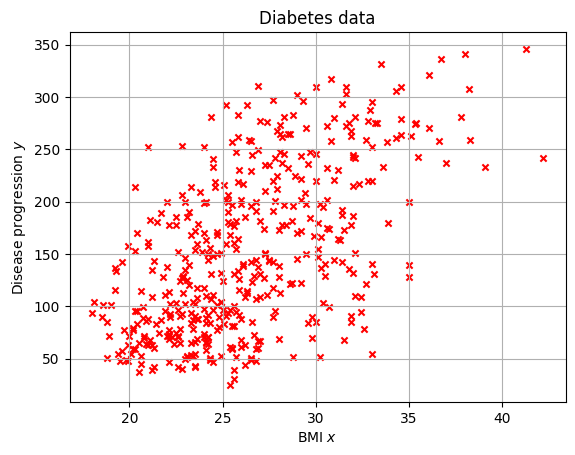

In [7]:
plt.scatter(x_train, y_train, marker='x', c='r', s=20)
plt.xlabel('BMI $x$')
plt.ylabel('Disease progression $y$')
plt.title('Diabetes data')
plt.grid(True)
plt.show()

There is a clear upward trend: patients with a higher BMI tend to have a higher disease progression. However, the points scatter a lot, so no straight line passes through all of them. We look for the line that fits the data **best**.

## Model function

The model for univariate linear regression is the straight line
$$
f_{w,b}(x) = wx + b ,
$$
where the slope $w$ (weight) and the intercept $b$ (bias) are the **parameters** of the model. For the training examples, the model predicts
$$
\hat y^{(i)} = f_{w,b}(x^{(i)}) = w x^{(i)} + b, \qquad i = 1, \dots, m .
$$
Different values of $w$ and $b$ give different lines. To try many of them, we write a function that takes $w$ and $b$ as inputs alongside $x$, first following the formula one example at a time.

In [8]:
def compute_model_output_loop(x, w, b):
    """
    Compute the predictions of a linear model, one example at a time.

    Args:
        x (ndarray (m,)): input values, m examples
        w, b (scalar)   : model parameters
    Returns:
        f_wb (ndarray (m,)): predictions
    """
    m = x.shape[0]
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w * x[i] + b
    return f_wb

### Do we need the loop? Vectorisation

Arithmetic on NumPy arrays acts **element by element**: `w * x + b` multiplies every element of `x` by `w` and adds `b`. The loop therefore collapses to a single line. This is called **vectorisation**: the code is shorter, closer to the mathematics and much faster, because the loop runs inside NumPy's compiled code. From now on we write vectorised code.

In [9]:
def compute_model_output(x, w, b):
    """Vectorised version: the predictions w * x + b for all examples at once."""
    return w * x + b

w, b = 5.0, 20.0
print(np.allclose(compute_model_output_loop(x_train, w, b),
                  compute_model_output(x_train, w, b)))

True


Both functions give the same predictions. Compare their speed:

In [10]:
%timeit compute_model_output_loop(x_train, w, b)
%timeit compute_model_output(x_train, w, b)

91 μs ± 3.48 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


1.71 μs ± 48.7 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


### Plotting the model

Since we will draw many lines, we wrap the plotting code in a function. A straight line is fixed by two points, so it is enough to evaluate the model at the smallest and largest BMI.

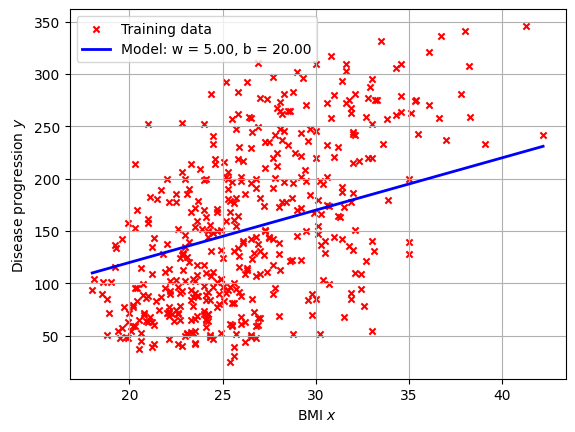

In [11]:
def plot_model(x, y, w, b):
    """Plot the training data and the line f(x) = w*x + b."""
    x_line = np.array([x.min(), x.max()])
    plt.scatter(x, y, marker='x', c='r', s=20, label='Training data')
    plt.plot(x_line, compute_model_output(x_line, w, b), 'b-', lw=2,
             label=f'Model: w = {w:.2f}, b = {b:.2f}')
    plt.xlabel('BMI $x$')
    plt.ylabel('Disease progression $y$')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_model(x_train, y_train, w=5.0, b=20.0)

This first guess follows the trend roughly but is too flat: it is too high for small BMI and too low for large BMI.

### Interpreting the parameters

In the lecture we saw that the best line for these data is $\hat y = 10.23\,x - 117.77$. In Lab 2 you will compute it yourself.

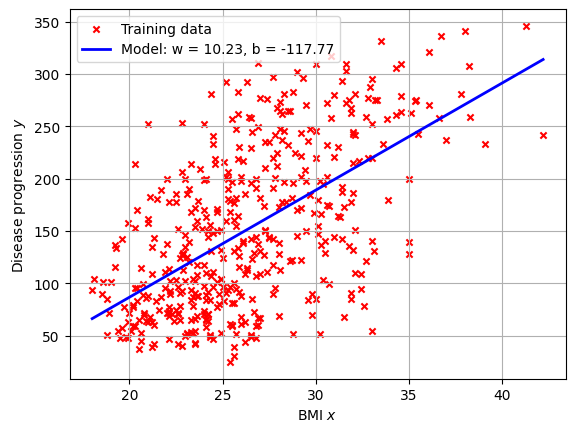

Predicted disease progression for BMI 30.0: 189.1

In [12]:
w_best, b_best = 10.23, -117.77
plot_model(x_train, y_train, w_best, b_best)

x_new = 30.0   # BMI of a new patient
print(f"Predicted disease progression for BMI {x_new}: "
      f"{compute_model_output(x_new, w_best, b_best):.1f}")

- The slope $w = 10.23$: each extra unit of BMI goes with about 10 points more disease progression, on average.
- The intercept $b = -117.77$ is the prediction for BMI $= 0$. It has no physical meaning: no patient has BMI $0$, and progression cannot be negative. The data cover BMI values from about 18 to 42, and predictions far outside this range should not be trusted.

## Challenges

1. Call `plot_model` with different values of $w$ and $b$. How does the line change if you change only $w$? Only $b$? Try to find values that fit the data well by eye.
2. Find the line that passes **exactly** through the first two training examples, $(x^{(1)}, y^{(1)}) = (32.1, 151)$ and $(x^{(2)}, y^{(2)}) = (21.6, 75)$. *Hint:* the line must satisfy
$$
w x^{(1)} + b = y^{(1)}, \qquad w x^{(2)} + b = y^{(2)},
$$
which are two linear equations for the two unknowns $w$ and $b$. Plot the line. Is it a good model for all $442$ patients?

::: {.callout-tip collapse="true" title="Solution to Challenge 2"}
Subtracting the second equation from the first eliminates $b$:
$$
w = \frac{y^{(1)} - y^{(2)}}{x^{(1)} - x^{(2)}}, \qquad b = y^{(1)} - w\,x^{(1)} .
$$

w = 7.2381, b = -81.3429
[  7.23809524 -81.34285714]


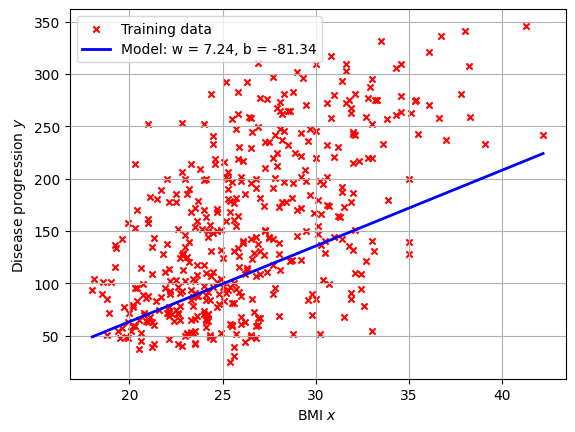

In [13]:
x1, y1 = x_train[0], y_train[0]
x2, y2 = x_train[1], y_train[1]
w_two = (y1 - y2) / (x1 - x2)
b_two = y1 - w_two * x1
print(f"w = {w_two:.4f}, b = {b_two:.4f}")

# The same result by solving the linear system A [w, b]^T = [y1, y2]^T
A = np.array([[x1, 1.0],
              [x2, 1.0]])
print(np.linalg.solve(A, np.array([y1, y2])))

plot_model(x_train, y_train, w_two, b_two)

The line passes exactly through the two chosen points but ignores the other $440$ patients: it is too flat and lies below most of the data for large BMI. A different pair of points would give a different line. With more than two points that do not lie on one line, no line passes through all of them, so we need a measure of how well a line fits **all** the data: the **cost function** of Lab 2.
:::

## Summary

- The training data are stored in 1D NumPy arrays `x_train` and `y_train`; $m$ is `x_train.shape[0]`, and the lecture's $x^{(i)}$ is `x_train[i-1]`.
- `np.savetxt` and `np.loadtxt` write and read numerical data in text files.
- The model $f_{w,b}(x) = wx + b$ is one vectorised line of code: `w * x + b`.
- The slope $w$ and the intercept $b$ determine the line. Do not trust predictions far outside the range of the data.

**Next (Lab 2):** a cost function that measures how well a line fits the data, and gradient descent to find the best $w$ and $b$.